

Objectif :

Optimiser les hyperparamètres des modèles retenus après la comparaison initiale.

Les modèles sélectionnés sont :

- RandomForest
- GradientBoosting

L'objectif est d'améliorer leurs performances tout en conservant une bonne capacité à détecter les signaux BUY, HOLD et SELL.

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import TimeSeriesSplit

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    classification_report,
    accuracy_score
)

import matplotlib.pyplot as plt

In [2]:
FINAL_PATH = Path("../data/final")

df = pd.read_csv(
    FINAL_PATH / "BTCUSD_final_dataset.csv"
)

print(df.shape)

df.head()

(4975, 22)


,close,volume,changePercent,vwap,return,return_1,return_3,return_7,volatility_5,volatility_20,...,dist_sma,dist_ema,rsi,BB_upper,BB_lower,BB_width,BB_percent,trend_signal,return_acceleration,target
0,5.06002,0,0.19842,5.04421,0.002002,0.002002,-0.001378,0.022412,0.009361,0.020009,...,-0.005510,0.001079,56.516697,5.299120,4.876987,0.082965,0.433591,0,0.007338,-1
1,5.04997,0,-0.73535,5.04934,-0.001986,-0.001986,-0.005324,0.009994,0.006291,0.018936,...,-0.006823,-0.000823,46.226400,5.295896,4.873428,0.083087,0.417882,0,-0.003988,-1
2,5.04370,0,-0.12238,5.04742,-0.001242,-0.001242,-0.001230,-0.005907,0.003068,0.018909,...,-0.007139,-0.001867,42.800418,5.290413,4.869515,0.082854,0.413841,0,0.000745,0
3,4.85000,0,-4.14451,4.95938,-0.038404,-0.038404,-0.041506,-0.055387,0.016647,0.017950,...,-0.040547,-0.036511,33.951625,5.248455,4.861473,0.076555,-0.029646,0,-0.037163,1
4,4.96000,0,2.26804,4.90275,0.022680,0.022680,-0.017816,-0.021117,0.022030,0.018709,...,-0.015865,-0.013281,41.406115,5.211809,4.868111,0.068195,0.267355,0,0.061085,1


In [3]:
X = df.drop(
    columns=["target"]
)

y = df["target"]

In [5]:
split = int(len(df)*0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [7]:
tscv = TimeSeriesSplit(
    n_splits=5
)

Nous utilisons TimeSeriesSplit afin de respecter la structure temporelle des données financières et éviter toute fuite d'information future.

In [8]:
rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

rf_grid = {

    "n_estimators":[100,200],

    "max_depth":[
        5,
        10,
        None
    ],

    "min_samples_split":[
        2,
        5
    ],

    "min_samples_leaf":[
        1,
        2
    ]
}

In [9]:
rf_search = GridSearchCV(

    estimator=rf,

    param_grid=rf_grid,

    cv=tscv,

    scoring="f1_macro",

    n_jobs=-1
)

rf_search.fit(
    X_train_scaled,
    y_train
)

print(
    rf_search.best_params_
)

print(
    rf_search.best_score_
)

{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
0.31031227393211613


In [10]:
gb = GradientBoostingClassifier(
    random_state=42
)

gb_grid = {

    "n_estimators":[100,200],

    "learning_rate":[
        0.05,
        0.1
    ],

    "max_depth":[
        3,
        5
    ],

    "min_samples_split":[
        2,
        5
    ],

    "min_samples_leaf":[
        1,
        2
    ]
}

In [11]:
gb_search = GridSearchCV(

    estimator=gb,

    param_grid=gb_grid,

    cv=tscv,

    scoring="f1_macro",

    n_jobs=-1
)

gb_search.fit(
    X_train_scaled,
    y_train
)

print(
    gb_search.best_params_
)

print(
    gb_search.best_score_
)

{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
0.33183322474327176


In [12]:
best_models = {

    "RandomForest":

    rf_search.best_estimator_,


    "GradientBoosting":

    gb_search.best_estimator_
}

In [13]:
results=[]

for model_name,model in best_models.items():

    y_pred=model.predict(
        X_test_scaled
    )

    report=classification_report(

        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    results.append({

        "Model":model_name,

        "Accuracy":
        report["accuracy"],

        "F1_BUY":
        report["1"]["f1-score"],

        "F1_SELL":
        report["-1"]["f1-score"],

        "F1_macro":
        report["macro avg"]["f1-score"]

    })

    print("\n"+"="*80)

    print(model_name)

    print("="*80)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


RandomForest
              precision    recall  f1-score   support

          -1       0.27      0.83      0.41       260
           0       0.44      0.12      0.19       416
           1       0.24      0.07      0.10       319

    accuracy                           0.29       995
   macro avg       0.32      0.34      0.23       995
weighted avg       0.33      0.29      0.22       995


GradientBoosting
              precision    recall  f1-score   support

          -1       0.30      0.53      0.38       260
           0       0.47      0.37      0.41       416
           1       0.30      0.20      0.24       319

    accuracy                           0.35       995
   macro avg       0.36      0.36      0.34       995
weighted avg       0.37      0.35      0.35       995



In [14]:
results_df = pd.DataFrame(
    results
)

results_df

,Model,Accuracy,F1_BUY,F1_SELL,F1_macro
0,RandomForest,0.287437,0.103448,0.407583,0.233356
1,GradientBoosting,0.354774,0.241509,0.380556,0.344292




Les graphiques permettent de comparer visuellement les modèles optimisés selon les métriques principales :

- F1_BUY : qualité du signal d'achat
- F1_SELL : qualité du signal de vente
- F1_macro : équilibre général entre les classes
- Accuracy : performance globale

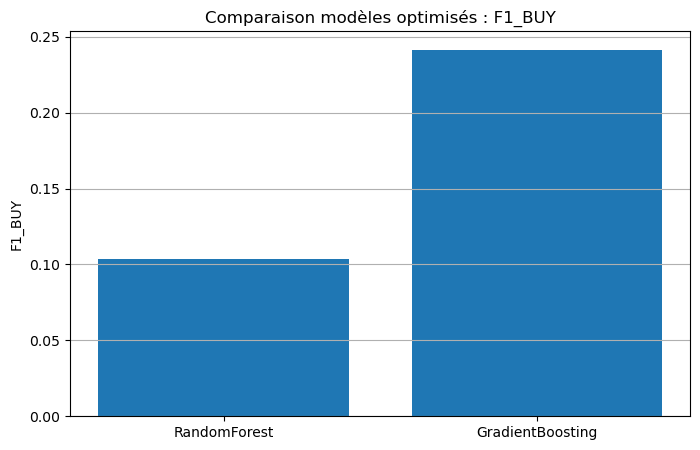

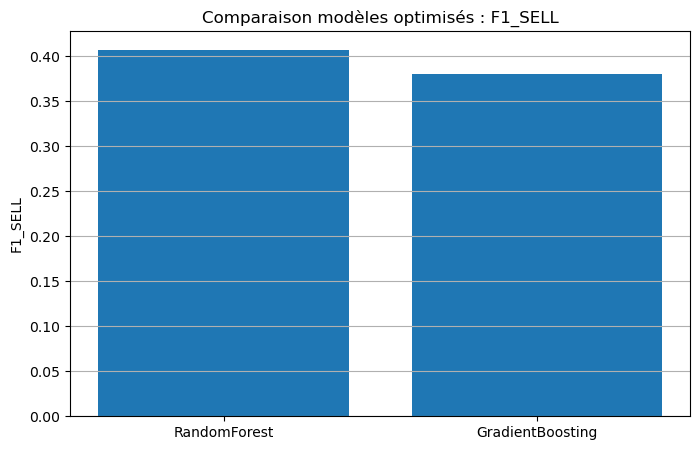

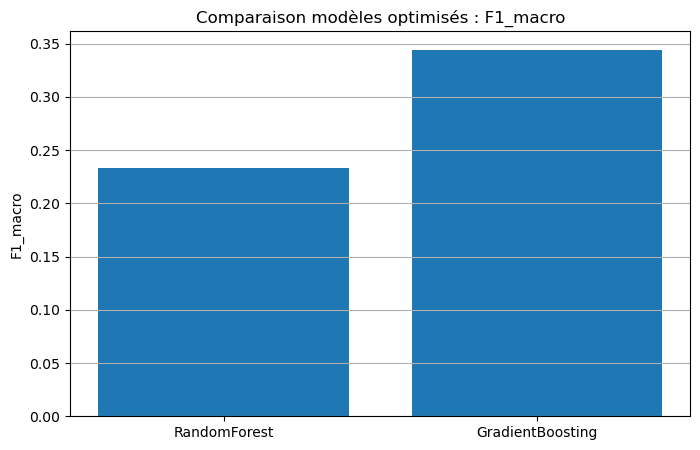

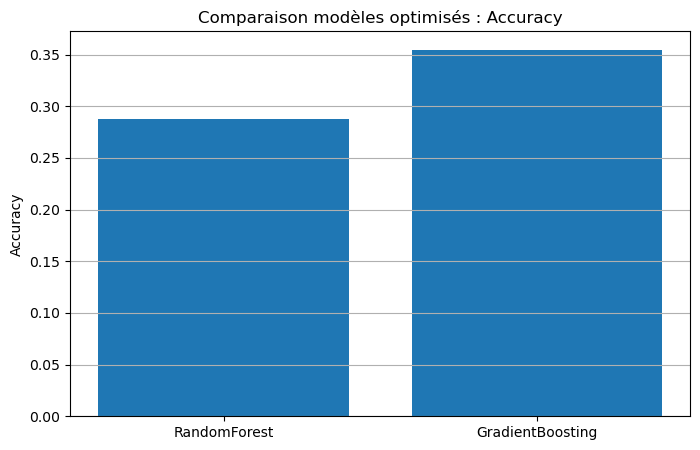

In [15]:
metrics=[

    "F1_BUY",
    "F1_SELL",
    "F1_macro",
    "Accuracy"
]

for metric in metrics:

    plt.figure(
        figsize=(8,5)
    )

    plt.bar(

        results_df["Model"],
        results_df[metric]
    )

    plt.title(
        f"Comparaison modèles optimisés : {metric}"
    )

    plt.ylabel(
        metric
    )

    plt.grid(
        axis="y"
    )

    plt.show()



Après optimisation des hyperparamètres :

- GradientBoosting présente les meilleures performances globales.
- Le modèle obtient un meilleur F1-score sur les signaux BUY.
- Le F1 macro est également supérieur, indiquant un meilleur équilibre entre les différentes classes.
- L'accuracy globale est également améliorée.

RandomForest conserve une légère avance sur les signaux SELL, mais l'écart reste limité.

Le modèle retenu pour la suite du projet est donc : GradientBoosting